# Crossbar ↔ digital-processor traffic for softmax offload (Llama 3 8B)

This CiM architecture only performs matrix-vector multiplies in the analog crossbar. The
softmax inside self-attention can't run there, so the QK^T score matrix has to leave the
chip for a digital processor, and the post-softmax probabilities have to come back before
the AV matmul. This notebook quantifies that round trip for Llama 3 8B
(`hidden=4096, n_heads=32, head_dim=128, n_layers=32`) across context lengths from 128 to
8192 tokens (Llama 3's native context), and compares it against the crossbar's own real
simulated matmul cost to find where the offload becomes the bottleneck.

Architecture: `macro=basic_analog`, `chip=cim_tile_array` (4x8 = 32 tiles, one per head),
`system=fetch_weights_hbm2`. For each stage (QK^T, AV) we run two real Timeloop/Accelergy
simulations:
- **baseline**: the score/probability tensor stays on-chip in `l2_shared_buf` (softmax assumed free)
- **offload**: that tensor is forced through the off-chip `main_memory` (HBM2) link instead,
  modeling the trip to the digital processor and back

The *difference* between these two real runs isolates the cost of the offload.

In [1]:
from _import_scripts import scripts
from scripts.utils import get_spec, run_mapper
import pytimeloop.timeloopfe.v4 as tl
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Llama 3 8B attention shape

Each attention head computes its own `S x S` score matrix, so the round-trip data volume
is driven by `N_HEADS` (32 query heads) regardless of GQA grouping on the K/V side —
GQA only changes weight reuse, not the size of the score matrix that has to go through
softmax.

In [2]:
HIDDEN_SIZE = 4096
N_HEADS = 32          # query heads (GQA's 8 kv heads don't change score-matrix size)
HEAD_DIM = HIDDEN_SIZE // N_HEADS  # 128
N_LAYERS = 32
BATCH = 1              # single-sequence prefill
SEQ_LENS = [128, 256, 512, 1024, 2048, 4096, 8192]

MACRO = 'basic_analog'
CHIP = 'cim_tile_array'
SYSTEM = 'fetch_weights_hbm2'
TILE_ROWS, TILE_COLS = 4, 8  # 32 tiles -> one per attention head

## Build and run the two matmul stages

`qk`: `Out[head, seq_q, seq_k] = sum_headdim Q[head, headdim, seq_q] * K[head, headdim, seq_k]`
(`Outputs` = pre-softmax scores, the tensor that must leave the crossbar)

`av`: `Out[head, headdim, seq_q] = sum_seq_k V[head, seq_k, headdim] * P[head, seq_k, seq_q]`
(`Inputs` = post-softmax probabilities, the tensor that must come back in)

We reuse the histogram shapes from the repo's `msft_phi_1_5` `SelfAttention` layer as a
stand-in activation distribution — only the problem *instance* (the actual Llama 3 8B
dimensions) is swapped in.

In [3]:
def build_spec(S: int, stage: str, offload: bool):
    M, C, P = (S, HEAD_DIM, S) if stage == 'qk' else (HEAD_DIM, S, S)
    spec = get_spec(
        macro=MACRO, chip=CHIP, system=SYSTEM,
        dnn='msft_phi_1_5', layer='001',  # histogram scaffolding only
        tile_rows=TILE_ROWS, tile_cols=TILE_COLS, max_utilization=True,
    )
    spec.problem.instance.update({'M': M, 'C': C, 'G': N_HEADS, 'P': P, 'N': BATCH})

    offload_dataspace = 'Outputs' if stage == 'qk' else 'Inputs'
    mm = spec.architecture.name2leaf('main_memory')
    if offload:
        l2 = spec.architecture.name2leaf('l2_shared_buf')
        mm.constraints.dataspace['keep_only'] = tl.constraints.ProblemDataspaceList(
            ['Weights', offload_dataspace]
        )
        l2.constraints.dataspace['keep_only'] = tl.constraints.ProblemDataspaceList(
            [d for d in ['Inputs', 'Outputs'] if d != offload_dataspace]
        )
    return spec, mm.attributes['width']


def run_combo(S: int, stage: str):
    base_spec, width = build_spec(S, stage, offload=False)
    baseline = run_mapper(base_spec)
    off_spec, _ = build_spec(S, stage, offload=True)
    offload = run_mapper(off_spec)
    return {'S': S, 'stage': stage, 'baseline': baseline, 'offload': offload, 'width': width}

In [4]:
raw_results = joblib.Parallel(n_jobs=8)(
    joblib.delayed(run_combo)(S, stage)
    for S in SEQ_LENS
    for stage in ['qk', 'av']
)

by_s = {S: {} for S in SEQ_LENS}
for r in raw_results:
    by_s[r['S']][r['stage']] = r

## Derive traffic, latency, and energy metrics

- **Compute latency/energy**: real simulated crossbar cost for QK^T + AV (baseline runs)
- **Offload data volume**: exact, from problem geometry — `N_HEADS * S^2` elements leave as
  scores and the same count returns as probabilities, each at the model's 8-bit precision
- **Offload energy**: the real `main_memory` (HBM2) energy delta between the offload and
  baseline runs — isolates exactly the cost of routing the score/probability tensor
  off-chip, using Accelergy's own characterized DRAM energy, not an assumed number
- **Offload time**: a bandwidth-bound estimate using `main_memory`'s configured channel
  width (128b, the real value from the architecture file) at the JEDEC HBM2 standard pin
  rate (2 Gb/s/pin -> 32 GB/s for a 128-bit channel). Timeloop's own cycle count doesn't
  stall for this off-chip hop (it assumes the access is fully hidden/pipelined), and
  CiMLoop's internal `GLOBAL_CYCLE_SECONDS` is tuned to the analog array's read-pulse
  timing (~10 MHz equivalent) rather than a real off-chip link clock, so reusing it here
  would overstate transfer time by orders of magnitude. The real HBM2 signaling rate keeps
  this estimate physically grounded instead.

**Caveat on the compute side:** these mapper runs use CiMLoop's `max_utilization` shortcut,
which assumes the array always operates at full utilization rather than running the full
mapper search. In this mode crossbar latency comes out *linear* in `S` (it scales with
`ArrayProcessor`'s automatic factor-filling rather than the full `O(S^2)` MAC growth), so
the compute-latency curve below is likely an underestimate at large `S` relative to a
realistic, fully-searched mapping. That makes the crossover point reported later a
conservative (early) one — a more realistic compute model would push it later, but
wouldn't change the qualitative O(S) vs O(S^2) story.

In [5]:
HBM2_GBPS_PER_PIN = 2.0  # JEDEC HBM2 standard signaling rate (Gb/s per pin)

rows = []
for S in SEQ_LENS:
    qk, av = by_s[S]['qk'], by_s[S]['av']
    qk_base, qk_off = qk['baseline'], qk['offload']
    av_base, av_off = av['baseline'], av['offload']

    compute_latency_s = qk_base.latency + av_base.latency
    compute_energy_j = qk_base.energy + av_base.energy

    offload_energy_j = (
        (qk_off.per_component_energy.get('main_memory', 0) - qk_base.per_component_energy.get('main_memory', 0))
        + (av_off.per_component_energy.get('main_memory', 0) - av_base.per_component_energy.get('main_memory', 0))
    )

    output_bits = qk_base.output_bits
    input_bits = qk_base.input_bits
    width_bits_per_channel = qk['width']
    hbm2_bandwidth_bps = width_bits_per_channel * HBM2_GBPS_PER_PIN * 1e9

    scores_out_bits = BATCH * N_HEADS * S * S * output_bits
    probs_in_bits = BATCH * N_HEADS * S * S * input_bits
    offload_bits = scores_out_bits + probs_in_bits
    offload_time_s = offload_bits / hbm2_bandwidth_bps

    rows.append({
        'S': S,
        'compute_latency_s': compute_latency_s,
        'compute_energy_j': compute_energy_j,
        'offload_bits': offload_bits,
        'offload_energy_j': offload_energy_j,
        'offload_time_s': offload_time_s,
    })

df = pd.DataFrame(rows)
df['model_compute_latency_s'] = df['compute_latency_s'] * N_LAYERS
df['model_compute_energy_j'] = df['compute_energy_j'] * N_LAYERS
df['model_offload_bits'] = df['offload_bits'] * N_LAYERS
df['model_offload_energy_j'] = df['offload_energy_j'] * N_LAYERS
df['model_offload_time_s'] = df['offload_time_s'] * N_LAYERS
df['offload_to_compute_latency_ratio'] = df['offload_time_s'] / df['compute_latency_s']
df['offload_to_compute_energy_ratio'] = df['offload_energy_j'] / df['compute_energy_j']
df

,S,compute_latency_s,compute_energy_j,offload_bits,offload_energy_j,offload_time_s,model_compute_latency_s,model_compute_energy_j,model_offload_bits,model_offload_energy_j,model_offload_time_s,offload_to_compute_latency_ratio,offload_to_compute_energy_ratio
0,128,0.006554,0.008157,8388608,0.002124,0.000033,0.209715,0.261020,268435456,0.067976,0.001049,0.005,0.260425
1,256,0.013107,0.014673,33554432,0.004257,0.000131,0.419430,0.469545,1073741824,0.136234,0.004194,0.010,0.290140
2,512,0.026214,0.027710,134217728,0.008512,0.000524,0.838861,0.886735,4294967296,0.272397,0.016777,0.020,0.307192
3,1024,0.052429,0.053780,536870912,0.017020,0.002097,1.677722,1.720975,17179869184,0.544654,0.067109,0.040,0.316480
4,2048,0.104858,0.105932,2147483648,0.034038,0.008389,3.355443,3.389820,68719476736,1.089224,0.268435,0.080,0.321322
5,4096,0.209715,0.210228,8589934592,0.067987,0.033554,6.710886,6.727286,274877906944,2.175576,1.073742,0.160,0.323396
6,8192,0.419430,0.418819,34359738368,0.136235,0.134218,13.421773,13.402195,1099511627776,4.359507,4.294967,0.320,0.325283


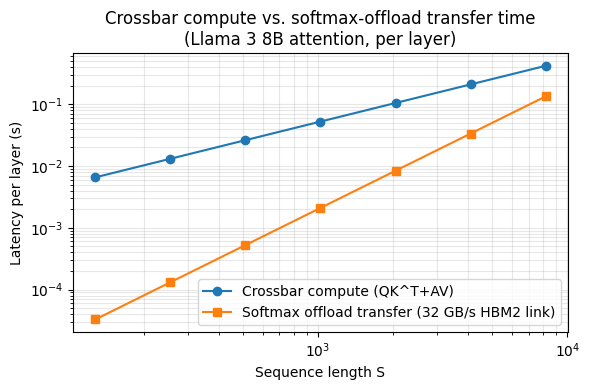

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(df['S'], df['compute_latency_s'], 'o-', label='Crossbar compute (QK^T+AV)')
ax.loglog(df['S'], df['offload_time_s'], 's-', label='Softmax offload transfer (32 GB/s HBM2 link)')
ax.set_xlabel('Sequence length S')
ax.set_ylabel('Latency per layer (s)')
ax.set_title('Crossbar compute vs. softmax-offload transfer time\n(Llama 3 8B attention, per layer)')
ax.legend()
ax.grid(True, which='both', alpha=0.3)
fig.tight_layout()

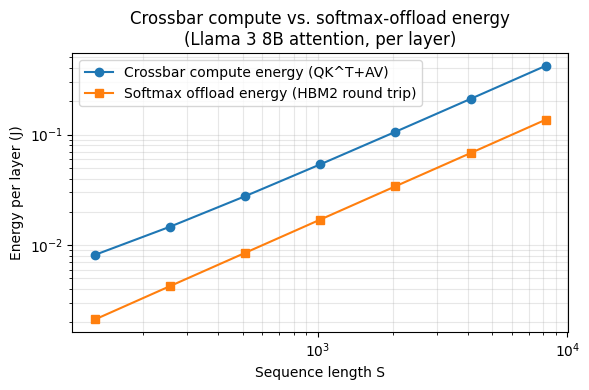

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(df['S'], df['compute_energy_j'], 'o-', label='Crossbar compute energy (QK^T+AV)')
ax.loglog(df['S'], df['offload_energy_j'], 's-', label='Softmax offload energy (HBM2 round trip)')
ax.set_xlabel('Sequence length S')
ax.set_ylabel('Energy per layer (J)')
ax.set_title('Crossbar compute vs. softmax-offload energy\n(Llama 3 8B attention, per layer)')
ax.legend()
ax.grid(True, which='both', alpha=0.3)
fig.tight_layout()

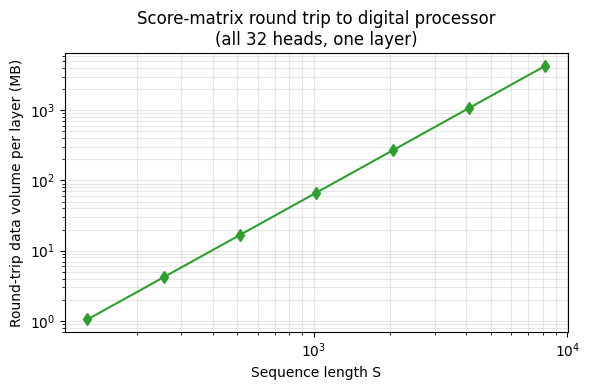

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(df['S'], df['offload_bits'] / 8 / 1e6, 'd-', color='tab:green')
ax.set_xlabel('Sequence length S')
ax.set_ylabel('Round-trip data volume per layer (MB)')
ax.set_title('Score-matrix round trip to digital processor\n(all 32 heads, one layer)')
ax.grid(True, which='both', alpha=0.3)
fig.tight_layout()

## Where does the offload become the bottleneck?

The offload data volume is exactly `O(S^2)` (score matrix size), but under CiMLoop's
`max_utilization` idealization the crossbar compute latency comes out `O(S)` (see caveat
above) — so the offload/compute ratio isn't flat, it grows linearly with `S` over this
sweep (it exactly doubles every time `S` doubles, see the table below). That means even
though offload transfer time stays below compute time across the swept 128-8192 range,
it is closing the gap as context length grows, and the trend extrapolates to a crossover
beyond this sweep. Energy tells a different, flatter story: offload energy holds at
roughly 30% of compute energy across all `S`, because both terms are real Accelergy
numbers driven by the same `O(S^2)` score-matrix size.

In [9]:
print(df[['S', 'compute_latency_s', 'offload_time_s', 'offload_to_compute_latency_ratio',
           'compute_energy_j', 'offload_energy_j', 'offload_to_compute_energy_ratio']]
      .to_string(index=False))

bottleneck = df[df['offload_to_compute_latency_ratio'] > 1]
last = df.iloc[-1]
if len(bottleneck):
    print(f"\nOffload transfer time exceeds crossbar compute time for S >= {bottleneck['S'].min()}")
else:
    extrapolated_s = last['S'] / last['offload_to_compute_latency_ratio']
    print(f"\nOffload transfer time stays below crossbar compute time across this sweep, "
          f"but the ratio grows linearly with S (it doubles every time S doubles, since "
          f"offload volume is O(S^2) against an idealized O(S) compute baseline).")
    print(f"Linear extrapolation puts the crossover at S ~= {extrapolated_s:.0f} tokens "
          f"(within Llama 3.1/3.2's extended-context range) -- and since the compute side "
          f"is an idealized lower bound (see caveat above), this is an optimistic estimate: "
          f"a realistically-mapped, non-max-utilization crossbar would scale compute closer "
          f"to O(S^2) too, which would push the crossover later, possibly indefinitely.")

s_max = df['S'].max()
row = df[df['S'] == s_max].iloc[0]
print(f"\nFull Llama 3 8B model (32 layers) at S={s_max}:")
print(f"  Crossbar compute: {row['model_compute_latency_s']*1e3:.3f} ms, {row['model_compute_energy_j']*1e3:.3f} mJ")
print(f"  Softmax offload:  {row['model_offload_time_s']*1e3:.3f} ms, {row['model_offload_energy_j']*1e3:.3f} mJ, "
      f"{row['model_offload_bits']/8/1e6:.1f} MB round trip")

   S  compute_latency_s  offload_time_s  offload_to_compute_latency_ratio  compute_energy_j  offload_energy_j  offload_to_compute_energy_ratio
 128           0.006554        0.000033                             0.005          0.008157          0.002124                         0.260425
 256           0.013107        0.000131                             0.010          0.014673          0.004257                         0.290140
 512           0.026214        0.000524                             0.020          0.027710          0.008512                         0.307192
1024           0.052429        0.002097                             0.040          0.053780          0.017020                         0.316480
2048           0.104858        0.008389                             0.080          0.105932          0.034038                         0.321322
4096           0.209715        0.033554                             0.160          0.210228          0.067987                         0.323396